<a href="https://colab.research.google.com/github/Mohsi777999/Machine-Learning-Labs/blob/main/Lab_10_K-Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**By Mohsin Ali**

### Task 1 & 2: Dataset Generation and Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# 1. Generate synthetic Mall Customer-like data (Annual Income vs Spending Score)
X, y_true = make_blobs(n_samples=300, centers=5, cluster_std=0.60, random_state=42)

# Convert to DataFrame
df = pd.DataFrame(X, columns=['Annual_Income', 'Spending_Score'])

# 2. Preprocess: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (300, 2)


,Annual_Income,Spending_Score
0,-1.377486,9.119033
1,1.135148,4.847704
2,-2.383879,7.838484
3,4.505801,2.401570
4,-3.306109,9.132403


### Task 3: Determine Optimal $K$ using the Elbow Method

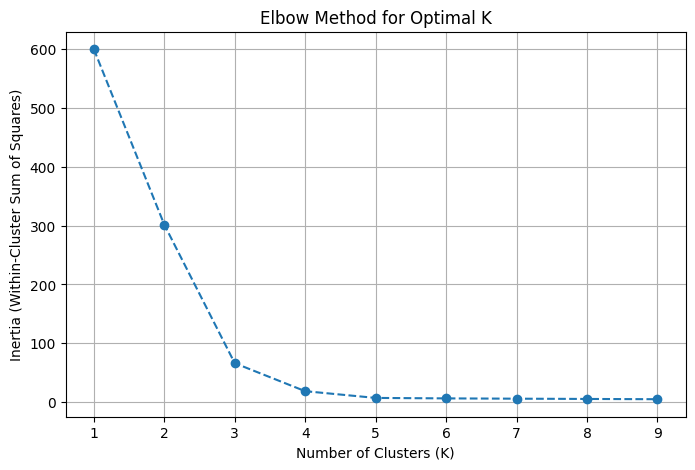

In [2]:
from sklearn.cluster import KMeans

inertia = []
K_range = range(1, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

### Task 4 & 5: Implement K-Means and Visualize Clusters

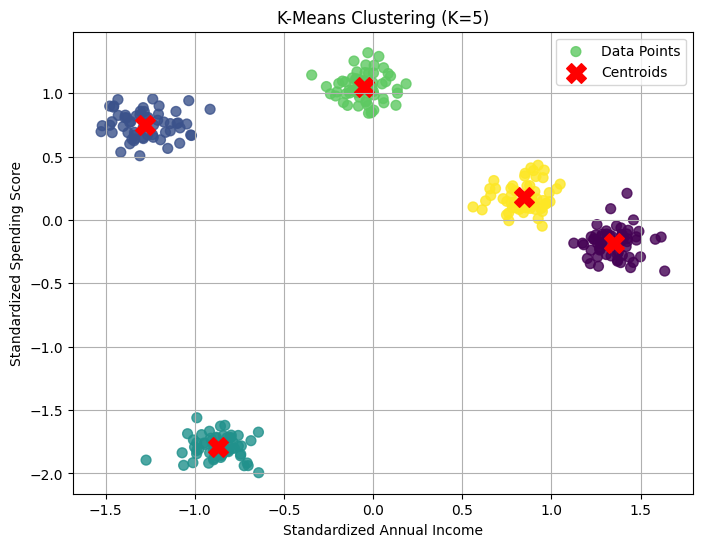

In [3]:
# Based on the elbow plot, optimal K is 5
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataframe
df['Cluster'] = y_kmeans

# Visualize clusters in 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, s=50, cmap='viridis', alpha=0.8, label='Data Points')

# Plot centroids
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Centroids')

plt.title(f'K-Means Clustering (K={optimal_k})')
plt.xlabel('Standardized Annual Income')
plt.ylabel('Standardized Spending Score')
plt.legend()
plt.grid(True)
plt.show()

### Task 6: Evaluation using Silhouette Score

In [4]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, y_kmeans)
print(f"Silhouette Score for K={optimal_k}: {score:.4f}")

Silhouette Score for K=5: 0.7975
